<a href="https://colab.research.google.com/github/pejmanrasti/SMART_MICROSCOPY/blob/main/TP1/TP1_U_Net_CycleGAN_Cytoland.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP 1 — From phase images to virtual fluorescence: U-Net vs CycleGAN vs Cytoland

**≈ 40 min + 10 min optional uncertainty part · Input: QPI (quantitative phase) of A549 cells → Output: nuclear fluorescence (Hoechst)**

**The biological question:** can we *predict* a nuclear stain from a label-free image, and how much should we trust the prediction?
We compare three ways of learning this:

| Model | What it learned from | In one sentence |
|---|---|---|
| **U-Net** | *Paired* images: the same cells seen in phase **and** fluorescence | Learns "this phase pixel → that fluorescence pixel" |
| **CycleGAN** | *Unpaired* images: a bag of phase images and a separate bag of fluorescence images, from **different** fields of view | Learns what fluorescence "looks like", without ever seeing a matching pair |
| **Cytoland (VSCyto2D)** | A large published model, pre-trained elsewhere | We just test it out of the box |

**Important rule:** CycleGAN never sees a matching (phase, fluorescence) pair during training. Matching pairs are used **only to evaluate** the models (and to train the U-Net).

All images are **real** data (A549 cells, Cytoland dataset). Models were trained by the instructor before class: here you **only use** them — no training, no GPU needed.

📚 [Cytoland paper](https://doi.org/10.1038/s42256-025-01046-2) · [VSCyto2D quickstart](https://virtualcellmodels.cziscience.com/quickstart/cytoland-quickstart) · [CycleGAN paper](https://arxiv.org/abs/1703.10593)

### How to use this notebook

- Run the cells **from top to bottom** with `Shift + Enter`.
- Cells marked **✏️ TODO** need a small change from you (usually one line).
- All the technical code (neural networks, metrics…) lives in the file `tp1_tools.py`, next to this notebook. You don't need to open it, but you can.
- The instructor gives you a folder with three files: `a549_qpi_nuclei_benchmark.npz`, `unet.pt`, `cyclegan.pt`. It can be anywhere on your computer: you just write its location **once**, in `DATA_FOLDER` below.

The functions you will use:

| Function | What it does |
|---|---|
| `load_classroom_data(DATA_FOLDER)` | loads the images |
| `load_unet(DATA_FOLDER)`, `load_cyclegan(DATA_FOLDER)` | loads a trained model |
| `predict(model, images)` | predicts fluorescence from QPI images |
| `predict_with_uncertainty(unet, images)` | prediction + uncertainty map (optional part) |
| `show_images({title: image, ...})` | shows images side by side |
| `compare_models(...)`, `plot_scores(...)` | computes and plots the scores |

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import zipfile

# Source zip file from drive, but unzipping locally to Colab's filesystem
zip_path = "/content/drive/MyDrive/01_Aussois_formation/TP1_data.zip"
destination_folder = "/content/01_Aussois_formation_TP1"

if os.path.exists(zip_path):
    print(f"Unzipping {zip_path} to {destination_folder}...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(destination_folder)
    print("Extraction complete!")

    # Set global DATA_FOLDER to the newly extracted local directory
    DATA_FOLDER = destination_folder
    print(f"DATA_FOLDER set to: {DATA_FOLDER}")
else:
    print(f"Zip file not found at {zip_path}. Please check the path.")

Unzipping /content/drive/MyDrive/01_Aussois_formation/TP1_data.zip to /content/01_Aussois_formation_TP1...
Extraction complete!
DATA_FOLDER set to: /content/01_Aussois_formation_TP1


In [4]:
import numpy as np
import sys

# ✏️ Location of the instructor's folder (relative to this notebook, or a full path).
# Examples: "classroom_materials", "../data/TP1", "/Users/me/Desktop/TP1_data"
FOLDER = "/content/01_Aussois_formation_TP1/TP1_data"

# Add the folder to the Python path so we can import tp1_tools
if FOLDER not in sys.path:
    sys.path.append(FOLDER)

from tp1_tools import *

## 1 · Look at the data (0–5 min)

In [5]:
DATA_FOLDER = "/content/01_Aussois_formation_TP1/TP1_data"

data = load_classroom_data(DATA_FOLDER)

qpi_images  = data["test_phase"]   # the label-free input images
true_nuclei = data["test_fluor"]   # the real Hoechst images (0 = dark, 1 = bright)

Training tiles : 36
Test tiles     : 12  (from 3 independent fields of view)
Tile size      : 256 x 256 pixels
Computing on   : cpu


Each test image is a small tile cut from a field of view (FOV). Let's look at one tile and its real fluorescence.

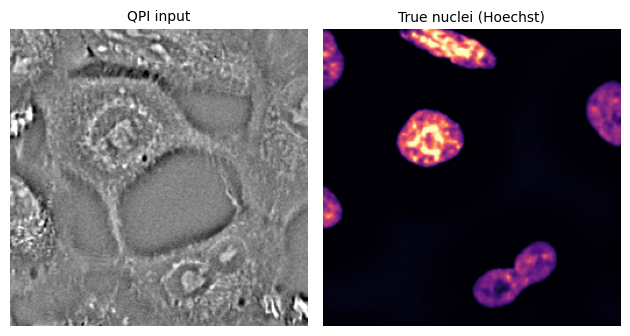

In [13]:
j = 10   # ✏️ tile number: try other values (0, 1, 2, ...)

show_images({
    "QPI input": qpi_images[j],
    "True nuclei (Hoechst)": true_nuclei[j],
})

## 2 · Model A — the paired U-Net (5–15 min)

The U-Net was trained on **matching pairs**. For every training image it compared its prediction with the real fluorescence, pixel by pixel, and tried to make the **average absolute difference** as small as possible (the *L1 loss*):

$$\text{L1 loss} = \text{average over pixels of } \big|\ \text{predicted fluorescence} - \text{true fluorescence}\ \big|$$

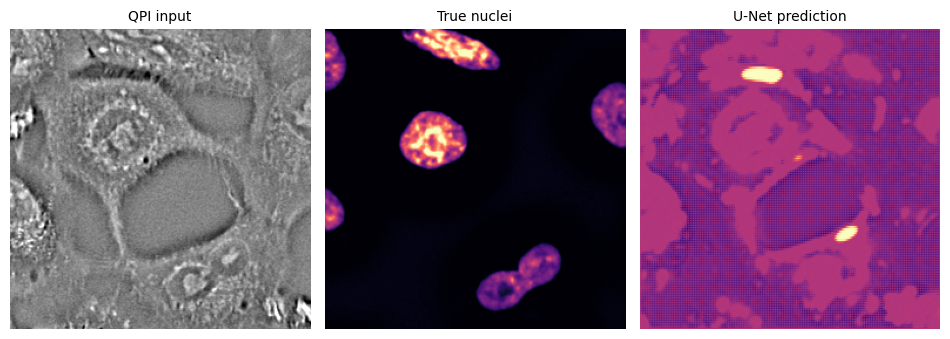

In [14]:
unet = load_unet(DATA_FOLDER)
unet_pred = predict(unet, qpi_images)   # one predicted image per test tile

show_images({
    "QPI input": qpi_images[j],
    "True nuclei": true_nuclei[j],
    "U-Net prediction": unet_pred[j],
})

**✏️ Exercise A — measure the error yourself.**
The *absolute error* of a pixel is `|true − predicted|`. In NumPy, `np.abs(a - b)` does this for every pixel at once.
Complete the line below, then look at **where** the U-Net makes mistakes.

In [ ]:
# TODO: compute the absolute error between true_nuclei[j] and unet_pred[j]
error_map = ...

print("Mean absolute error (MAE) on this tile:", round(float(np.mean(error_map)), 4))
show_images({"True nuclei": true_nuclei[j], "U-Net prediction": unet_pred[j], "U-Net error": error_map})

**Question 1.** Are the errors mostly inside nuclei, at their borders, or in the background? Why could a pixel-by-pixel average loss give **blurry** nuclei or miss **rare** structures (e.g. mitotic nuclei)?

## 3 · Optional (≈ 10 min) — How sure is the U-Net? (MC Dropout)

**Idea:** a normal network gives one answer. Here the U-Net was trained with *dropout* (it randomly switches off some of its internal units). If we keep dropout **on** when predicting and run the model many times (`K` times), we get slightly different predictions each time:

- the **average** of the K predictions → the predicted fluorescence;
- the **standard deviation** (spread) of the K predictions → an *uncertainty map*: where the predictions disagree, the model is less sure.

⚠️ Keep in mind:
- The real fluorescence is **not** used to build the uncertainty map — only to check it afterwards.
- This uncertainty only reflects the model's own doubt. It does **not** include camera / photon noise and it is **not** a calibrated confidence interval. On very unusual images, a model can be wrong *and* confident.

In [ ]:
K = 16   # number of repeated predictions

# TODO: use predict_with_uncertainty(...) on the U-Net and the QPI images, with n_repeats=K
mc_mean, mc_std = ...

show_images({
    "MC mean prediction": mc_mean[j],
    "MC std (uncertainty)": mc_std[j],
    "True nuclei": true_nuclei[j],
    "Absolute error": np.abs(mc_mean[j] - true_nuclei[j]),
})

Do the uncertain pixels coincide with the wrong pixels? We sort all pixels into 5 groups, from the least to the most uncertain, and look at the average error in each group.

In [ ]:
uncertainty_vs_error(true_nuclei, mc_mean, mc_std)

**Discussion (2 min).** Imagine a smart microscope that predicts fluorescence and only acquires a *real* fluorescence image when needed (to limit phototoxicity). To decide **where** to acquire next, would you only look at the highest uncertainty? What else matters: the *biological* importance of the error, the light dose / exposure cost…?

*Optional:* change `K` to 5, then 20, and re-run. What changes is how *stable* the uncertainty estimate is — not the model itself.

*Note:* for the rest of the practical we use the normal U-Net prediction `unet_pred` (dropout off).

## 4 · Model B — the unpaired CycleGAN (15–25 min)

CycleGAN learns with two "translators" (phase → fluorescence and fluorescence → phase) and two "critics" that try to tell real images from generated ones. Its main rule is **cycle consistency**: if you translate a phase image into fluorescence and then back into phase, you should recover the original image.

$$\text{phase} \;\rightarrow\; \text{fake fluorescence} \;\rightarrow\; \text{back to phase} \;\approx\; \text{original phase}$$

There is **no** term comparing a prediction with its true matching fluorescence. Let's first check that the two training domains really came from **different** fields of view:

In [15]:
check_unpaired_split(data)

FOVs used for the PHASE domain       : [np.str_('train_1'), np.str_('train_11'), np.str_('train_14'), np.str_('train_17'), np.str_('train_19'), np.str_('train_22')]
FOVs used for the FLUORESCENCE domain: [np.str_('train_12'), np.str_('train_13'), np.str_('train_16'), np.str_('train_18'), np.str_('train_2'), np.str_('train_21')]
FOVs in both domains                 : none
-> CycleGAN saw 18 phase tiles and 18 fluorescence tiles, never as pairs.


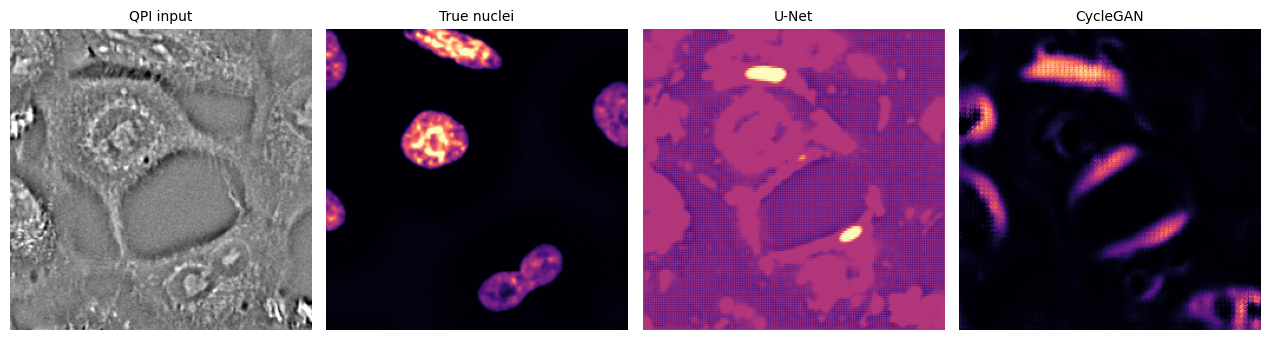

In [16]:
cyclegan = load_cyclegan(DATA_FOLDER)
cyclegan_pred = predict(cyclegan, qpi_images)

show_images({
    "QPI input": qpi_images[j],
    "True nuclei": true_nuclei[j],
    "U-Net": unet_pred[j],
    "CycleGAN": cyclegan_pred[j],
})

**Question 2.** Cycle consistency checks that the round trip *phase → fluorescence → phase* works. Does that guarantee that each generated nucleus is at the position of a **real** nucleus? Why or why not?

## 5 · Model C — Cytoland, a large pre-trained model (25–32 min)

The instructor ran the official **Cytoland VSCyto2D** model on the **same** test QPI images. We don't train it, we just use its predictions. (Cytoland also predicts membranes; here we only compare **nuclei**.)

*Intensity note:* Cytoland outputs values in its own units, not camera counts. Its predictions were therefore put on the 0–1 scale with a fixed rule computed on **training** images only (same recipe as for the real Hoechst images) — never adjusted on the test images.

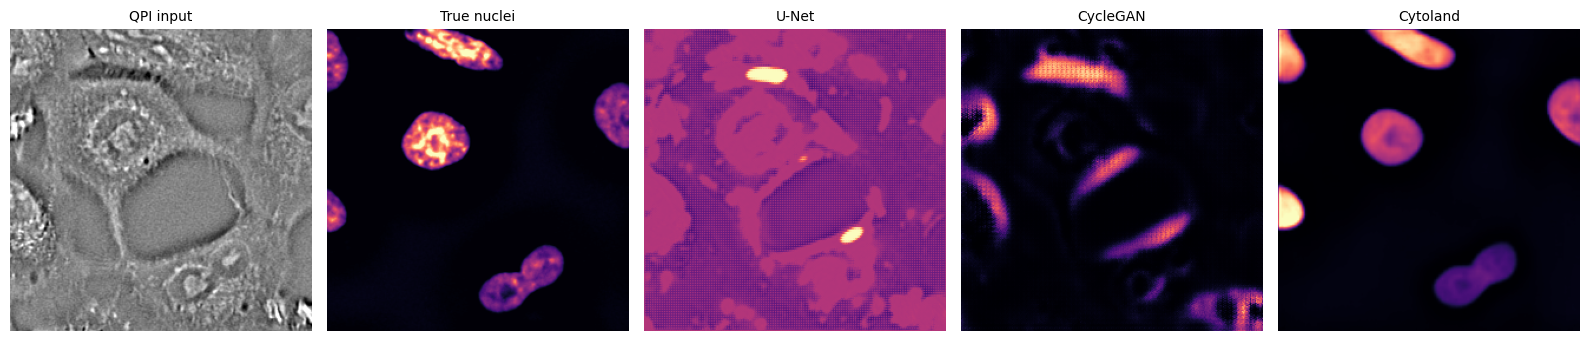

In [17]:
cytoland_pred = data["cytoland_test"]

show_images({
    "QPI input": qpi_images[j],
    "True nuclei": true_nuclei[j],
    "U-Net": unet_pred[j],
    "CycleGAN": cyclegan_pred[j],
    "Cytoland": cytoland_pred[j],
})

## 6 · Which model is best? Measure it (32–40 min)

We score each prediction against the real fluorescence with three numbers:

| Score | What it measures | Better when… |
|---|---|---|
| **MAE** (mean absolute error) | Are the *intensities* right? (what you computed in Exercise A) | **lower** |
| **SSIM** (structural similarity) | Are the *shapes and textures* right? | closer to **1** |
| **Pearson** correlation | Do bright/dark regions *vary together*, even if the overall brightness differs? | closer to **1** |

All images share the same fixed 0–1 intensity scale (set on training data only). We never rescale a prediction to make it look better.

**✏️ Exercise B.** Complete the dictionary with the two missing predictions, then run the cell.

In [ ]:
predictions = {
    "U-Net (paired)":        unet_pred,
    "CycleGAN (unpaired)":   None,   # TODO
    "Cytoland (pretrained)": None,   # TODO
}

results = compare_models(true_nuclei, predictions, data["test_fov_ids"])
plot_scores(results)
results.groupby("model")[["MAE", "SSIM", "Pearson"]].mean().round(3)

Several tiles come from the **same** field of view, so they are not independent replicates. Let's also look at the scores **per field of view**:

In [ ]:
results.groupby(["model", "fov"])[["MAE", "SSIM", "Pearson"]].mean().round(3)

Finally, the error maps of the three models on the same tile (same colour scale for all three):

In [ ]:
show_images({
    "U-Net error":    np.abs(true_nuclei[j] - unet_pred[j]),
    "CycleGAN error": np.abs(true_nuclei[j] - cyclegan_pred[j]),
    "Cytoland error": np.abs(true_nuclei[j] - cytoland_pred[j]),
})

### Interpretation questions

1. Rank the models for two different goals: **(a)** counting / segmenting nuclei, **(b)** measuring nuclear intensity (e.g. DNA content). Is the ranking the same?
2. Which model *looks* the most realistic? Is that necessarily the most faithful to the real biology?
3. Cytoland was trained on much more data than our two small models. Why is this **not** a fair, controlled comparison?
4. Why should the test images come from **other** fields of view — and ideally from other microscopes or cell lines?
5. If CycleGAN draws a bright nucleus where there is none, which score or which biological analysis would reveal it?

**There is no expected "right" ranking: the best model is measured, not assumed.**